# Part 3B: PyTorch dataset and split validation

This notebook validates the Part 3A CAM_FRONT exports through ScenarioForge's reusable PyTorch Dataset, paired transforms, scene split manifest, and detection DataLoader. It does not instantiate a detector or train a model. Run it with the separate `.venv-ml` kernel after creating `scene_split_seed42.json` using `scripts/prepare_vision_data.py split --seed 42`.

In [2]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import torch
from matplotlib.patches import Rectangle

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
if str(project_root / "src") not in sys.path:
    sys.path.insert(0, str(project_root / "src"))

from scenarioforge.vision_data.dataloader import (
    make_detection_dataloader,
    make_split_datasets,
    select_training_subset,
)
from scenarioforge.vision_data.splits import (
    load_split_manifest,
    validate_equal_training_budgets,
    validate_split_manifest,
)
from scenarioforge.vision_data.statistics import (
    compute_split_statistics,
    load_csv_rows,
)
from scenarioforge.vision_data.transforms import (
    build_eval_transforms,
    build_train_transforms,
)

vision_dir = project_root / "data" / "processed" / "vision"
dataset_root = Path(__import__("os").environ.get("NUSCENES_ROOT", project_root / "data" / "downloaded-dataset"))
split_path = vision_dir / "splits" / "scene_split_seed42.json"
assert split_path.is_file(), "Create the scene split first with scripts/prepare_vision_data.py split --seed 42"
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Dataset root:", dataset_root)
print("Split manifest:", split_path)

PyTorch: 2.15.0+cu132
CUDA available: True
Dataset root: d:\1Projectss\2027Application-projects\ScenarioForge\data\downloaded-dataset
Split manifest: d:\1Projectss\2027Application-projects\ScenarioForge\data\processed\vision\splits\scene_split_seed42.json


## Load and validate the saved scene split

The split assigns complete scenes, not individual frames. The loader checks the manifest digest, scene/sample exclusivity, and that every eligible image-manifest sample is assigned once.

In [3]:
image_rows = load_csv_rows(vision_dir / "image_manifest.csv")
annotation_rows = load_csv_rows(vision_dir / "annotations.csv")
dataset_manifest = json.loads((vision_dir / "dataset_manifest.json").read_text(encoding="utf-8"))
dataset_version = dataset_manifest["dataset_version"]
split_manifest = load_split_manifest(split_path, image_rows=image_rows, dataset_version=dataset_version)
split_integrity = validate_split_manifest(split_manifest, image_rows, dataset_version=dataset_version)
split_integrity

{'valid': True,
 'scene_overlap_count': 0,
 'sample_overlap_count': 0,
 'scene_count_by_split': {'train': 6, 'validation': 2, 'test': 2},
 'sample_count_by_split': {'train': 242, 'validation': 80, 'test': 82},
 'manifest_digest': 'd93c15fac3e798343ea95fcefea3c03a0b189a0b9036b3f355354550109bf2ab',
 'dataset_version': 'v1.0-mini',
 'inventory_digest': '0898a28fd93c46ea44eac57b728739aeb90d455431c4a1a210e37cd2ee483a98',
 'image_manifest_coverage_checked': True}

## Build train, validation, and test datasets

Evaluation uses deterministic resize-plus-tensor conversion. Training uses the paired transform API; horizontal flipping is disabled because mirroring can alter driving-scene semantics. Images are RGB float32 in `[0,1]`; boxes are rescaled in lockstep.

In [4]:
image_size = (450, 800)
datasets = make_split_datasets(
    dataset_root=str(dataset_root),
    annotations_csv=str(vision_dir / "annotations.csv"),
    image_manifest_csv=str(vision_dir / "image_manifest.csv"),
    category_mapping_json=str(vision_dir / "category_mapping.json"),
    split_manifest=split_manifest,
    transforms={
        "train": build_train_transforms(image_size),
        "validation": build_eval_transforms(image_size),
        "test": build_eval_transforms(image_size),
    },
)
for split, dataset in datasets.items():
    print(f"{split}: {len(dataset)} images, {sum(dataset.annotation_counts.values())} boxes, {len(set(dataset.scene_tokens))} scenes")
print("Source ID -> model label:", datasets["train"].source_id_to_model_label)
print("Model label -> source ID:", datasets["train"].model_label_to_source_id)

train: 242 images, 3636 boxes, 6 scenes
validation: 80 images, 952 boxes, 2 scenes
test: 82 images, 737 boxes, 2 scenes
Source ID -> model label: {1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7, 8: 8, 9: 9, 10: 10}
Model label -> source ID: {1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7, 8: 8, 9: 9, 10: 10}


## Inspect individual samples

Show a training image with many boxes, one with few boxes, and a zero-annotation sample when available. The plotting code only displays samples returned by the Dataset; projection and class mapping remain in reusable package code.

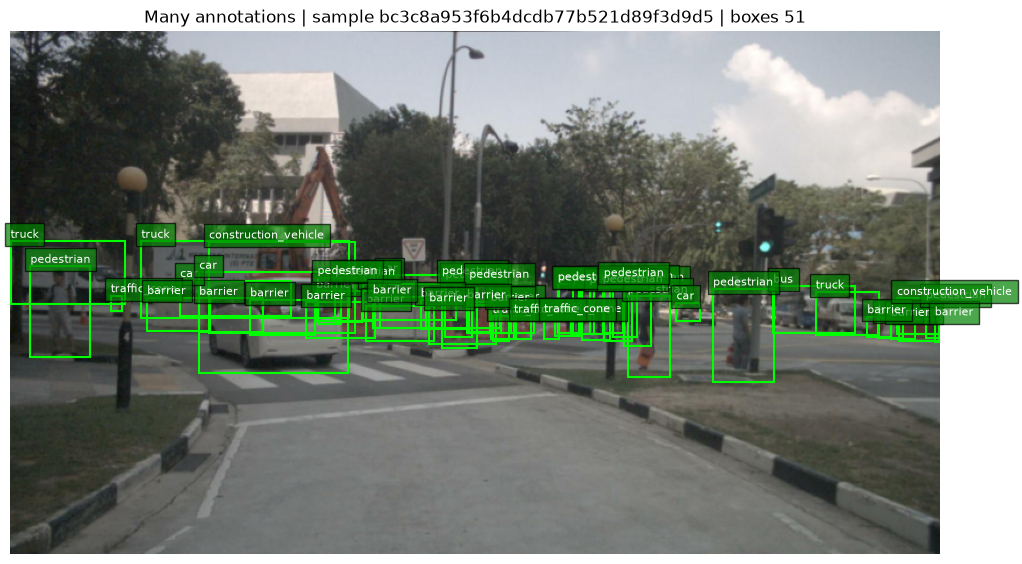

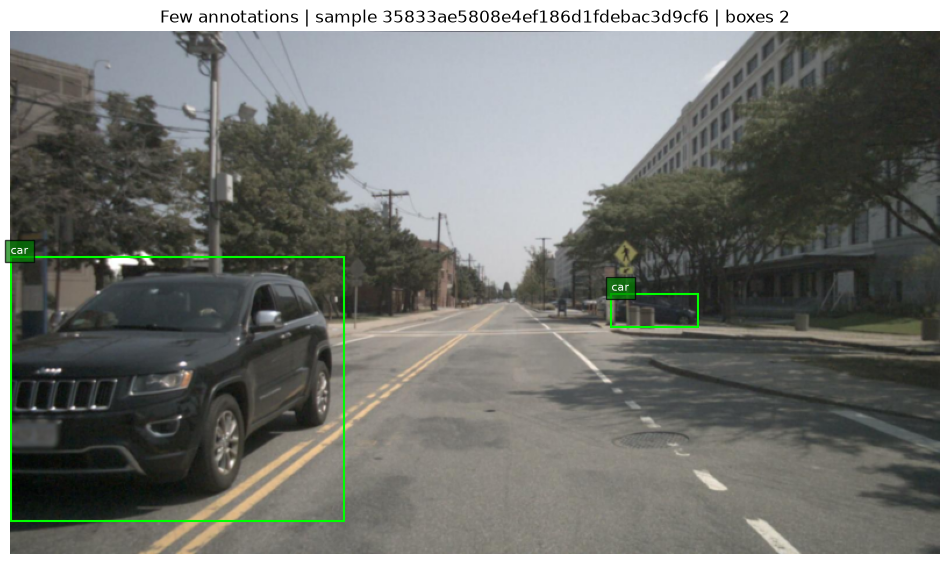

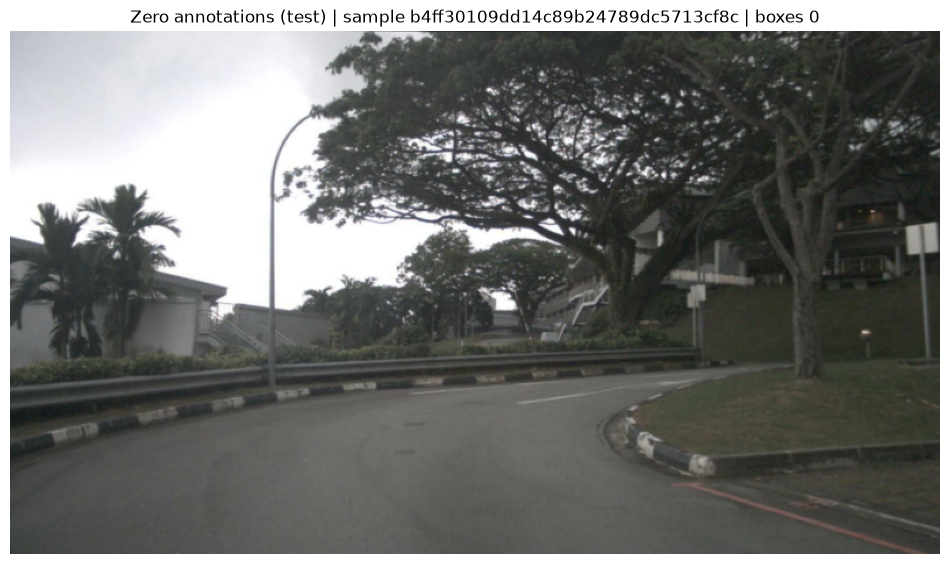

In [5]:
mapping_payload = json.loads((vision_dir / "category_mapping.json").read_text(encoding="utf-8"))
source_names = {int(item["class_id"]): item["name"] for item in mapping_payload["classes"]}

def show_sample(dataset, index, title):
    image, target = dataset[index]
    figure, axis = plt.subplots(figsize=(12, 7))
    axis.imshow(image.permute(1, 2, 0).cpu().numpy())
    for box, label in zip(target["boxes"].cpu().numpy(), target["labels"].cpu().tolist()):
        x_min, y_min, x_max, y_max = box
        axis.add_patch(Rectangle((x_min, y_min), x_max - x_min, y_max - y_min, fill=False, edgecolor="lime", linewidth=1.5))
        source_id = dataset.model_label_to_source_id[label]
        axis.text(x_min, max(0, y_min - 3), source_names[source_id], color="white", fontsize=8, bbox={"facecolor": "green", "alpha": 0.7})
    axis.set_title(f"{title} | sample {dataset.sample_tokens[index]} | boxes {len(target['labels'])}")
    axis.axis("off")
    plt.show()

train_dataset = datasets["train"]
many_index = max(range(len(train_dataset)), key=lambda index: train_dataset.annotation_counts[train_dataset.sample_tokens[index]])
few_nonempty = [index for index in range(len(train_dataset)) if 0 < train_dataset.annotation_counts[train_dataset.sample_tokens[index]] < train_dataset.annotation_counts[train_dataset.sample_tokens[many_index]]]
few_index = min(few_nonempty, key=lambda index: train_dataset.annotation_counts[train_dataset.sample_tokens[index]]) if few_nonempty else many_index
show_sample(train_dataset, many_index, "Many annotations")
show_sample(train_dataset, few_index, "Few annotations")

empty_candidates = [(split, index) for split, dataset in datasets.items() for index, sample in enumerate(dataset.sample_tokens) if dataset.annotation_counts[sample] == 0]
if empty_candidates:
    empty_split, empty_index = empty_candidates[0]
    show_sample(datasets[empty_split], empty_index, f"Zero annotations ({empty_split})")
else:
    print("No zero-annotation image exists in this split; inspect the lowest-count sample instead.")

## Fetch real DataLoader batches

Detection batches preserve the per-image target dictionaries instead of stacking variable-length boxes. The default worker count is zero for Windows compatibility; the sampler is seeded.

In [6]:
train_loader = make_detection_dataloader(train_dataset, batch_size=2, shuffle=True, seed=42, num_workers=0)
batch_images, batch_targets = next(iter(train_loader))
print("Batch image count:", len(batch_images))
for index, (image, target) in enumerate(zip(batch_images, batch_targets)):
    print(index, "image", tuple(image.shape), image.dtype, "boxes", tuple(target["boxes"].shape), target["boxes"].dtype, "labels", target["labels"].tolist(), "image_id", target["image_id"].item())
assert all(image.ndim == 3 and image.shape[0] == 3 and image.dtype == torch.float32 for image in batch_images)
assert all(target["boxes"].ndim == 2 and target["boxes"].shape[1] == 4 for target in batch_targets)

Batch image count: 2
0 image (3, 450, 800) torch.float32 boxes (20, 4) torch.float32 labels [2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 5, 5, 1, 1, 1] image_id 1217745939936804007
1 image (3, 450, 800) torch.float32 boxes (19, 4) torch.float32 labels [3, 1, 1, 1, 1, 1, 9, 1, 9, 5, 5, 1, 3, 1, 1, 1, 1, 1, 1] image_id 1769597048986535611


## Compare split class/scene distributions and leakage

Counts are descriptive only. Ten nuScenes-mini scenes cannot provide stable held-out support for every class; this split is not balanced.

In [7]:
statistics = compute_split_statistics(
    image_rows,
    annotation_rows,
    split_manifest,
    dataset_root,
    dataset_version=dataset_version,
    selected_training_samples=list(train_dataset.sample_tokens[: min(12, len(train_dataset))]),
)
for split, values in statistics["splits"].items():
    print(f"{split}: scenes={values['scene_count']}, images={values['image_count']}, boxes={values['annotation_count']}, empty={values['empty_image_count']}")
    print(" classes:", values["class_distribution"])
    print(" scenes:", values["images_per_scene"])

train_samples = set(split_manifest["sample_tokens"]["train"])
validation_samples = set(split_manifest["sample_tokens"]["validation"])
test_samples = set(split_manifest["sample_tokens"]["test"])
train_scenes = set(split_manifest["scene_tokens"]["train"])
validation_scenes = set(split_manifest["scene_tokens"]["validation"])
test_scenes = set(split_manifest["scene_tokens"]["test"])
print("Leakage report:", statistics["leakage_validation"])
assert not (train_samples & validation_samples or train_samples & test_samples or validation_samples & test_samples)
assert not (train_scenes & validation_scenes or train_scenes & test_scenes or validation_scenes & test_scenes)
equal_budget = validate_equal_training_budgets(
    split_manifest,
    {"random": train_dataset.sample_tokens[:12], "diversity": train_dataset.sample_tokens[12:24]},
    image_rows=image_rows,
    dataset_version=dataset_version,
)
print("Equal future curation budget guard:", equal_budget["common_training_budget"])
print("No held-out scene/sample overlaps:", True)

train: scenes=6, images=242, boxes=3636, empty=0
 classes: {'barrier': 527, 'bicycle': 54, 'bus': 136, 'car': 1263, 'construction_vehicle': 97, 'motorcycle': 44, 'pedestrian': 814, 'traffic_cone': 580, 'trailer': 17, 'truck': 104}
 scenes: {'6f83169d067343658251f72e1dd17dbc': 41, 'bebf5f5b2a674631ab5c88fd1aa9e87a': 41, 'cc8c0bf57f984915a77078b10eb33198': 39, 'd25718445d89453381c659b9c8734939': 41, 'de7d80a1f5fb4c3e82ce8a4f213b450a': 40, 'e233467e827140efa4b42d2b4c435855': 40}
validation: scenes=2, images=80, boxes=952, empty=0
 classes: {'bicycle': 15, 'bus': 11, 'car': 648, 'motorcycle': 25, 'pedestrian': 198, 'traffic_cone': 11, 'truck': 44}
 scenes: {'c5224b9b454b4ded9b5d2d2634bbda8a': 40, 'fcbccedd61424f1b85dcbf8f897f9754': 40}
test: scenes=2, images=82, boxes=737, empty=1
 classes: {'bicycle': 13, 'bus': 35, 'car': 440, 'construction_vehicle': 4, 'motorcycle': 78, 'pedestrian': 122, 'traffic_cone': 3, 'truck': 42}
 scenes: {'2fc3753772e241f2ab2cd16a784cc680': 41, '325cef682f064c55

## Limitations

The saved seed-42 smoke-test partition is 6/2/2 scenes and has absent validation/test support for some rare categories. Results on it would be exploratory only. This notebook validates input loading and split membership; it does not train a model, score curation strategies, alter held-out membership, or claim model performance.